# Finance Prediction
### Comparing RNN, LSTM, GRU, BiLSTM, CNN-LSTM, TCN and Transformer for Multi-Horizon Stock Forecasting (GOOG)

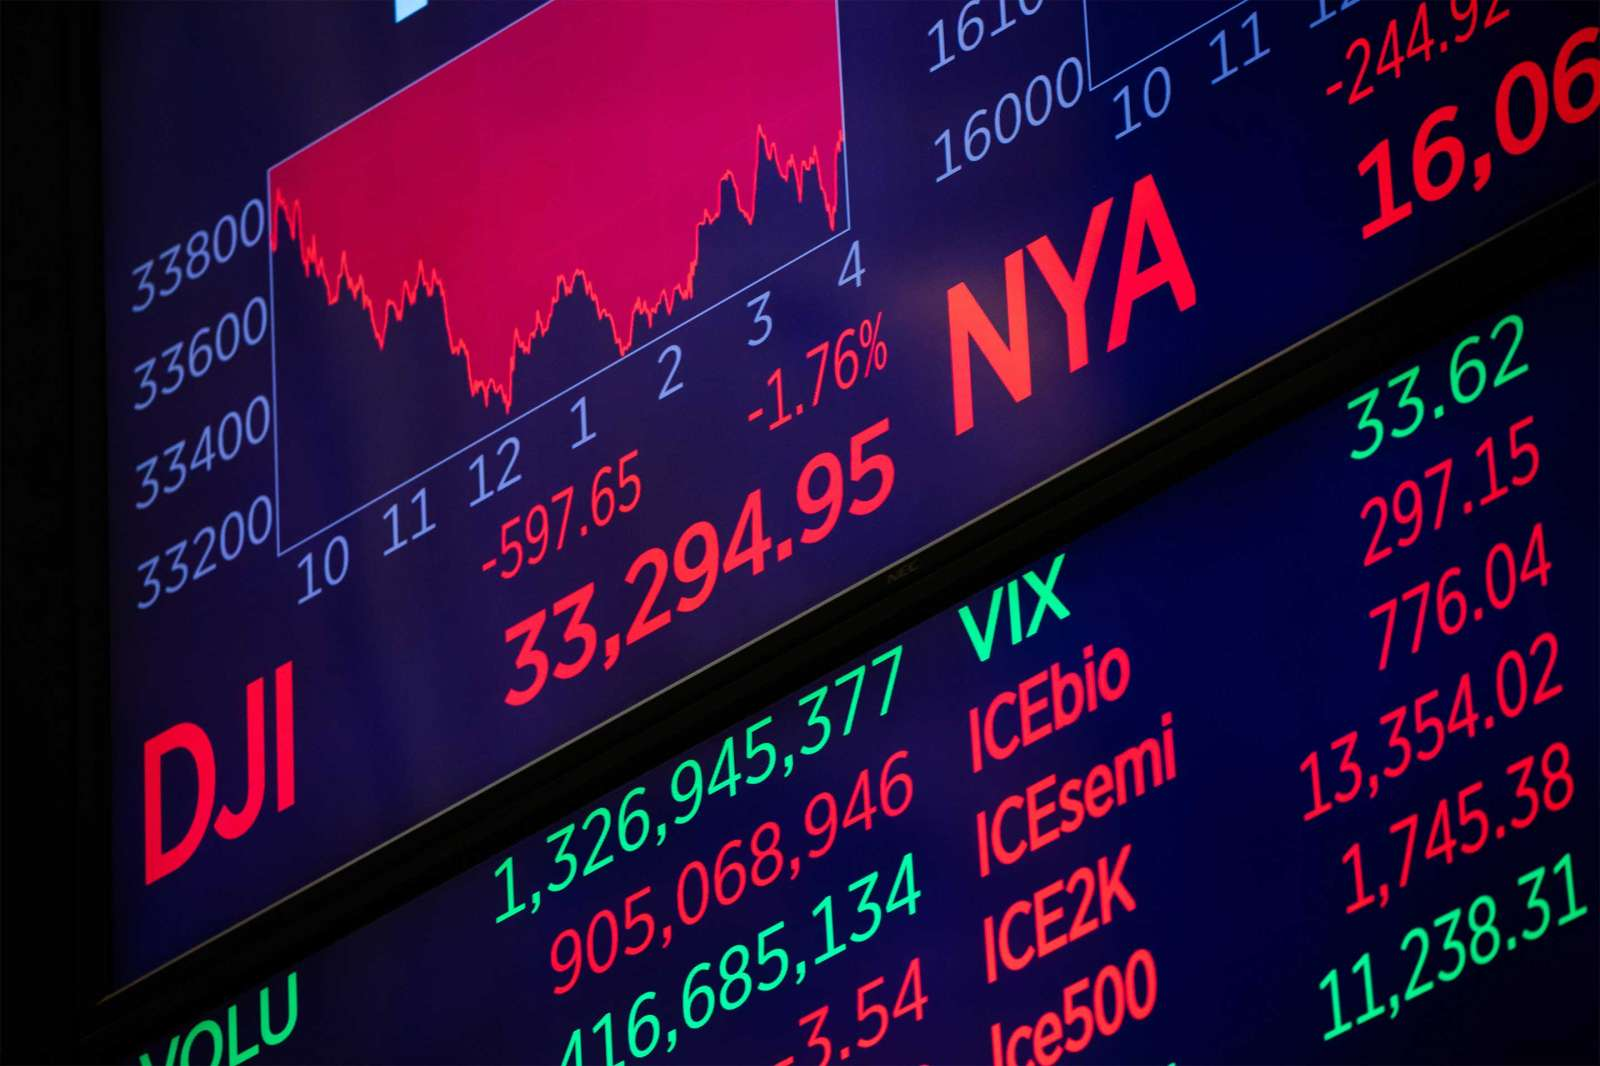

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">Dataset</b></p>
<p>The data are <b>daily stock prices of Alphabet (ticker GOOG)</b>: <b>open, high, low, close and volume</b> for <b>1,258 trading days</b>, from <b>2016-06-14</b> to <b>2021-06-11</b>, with no missing values. Prices rise from roughly 670 to over 2,500 USD over the period and cover very different market regimes, including the COVID-19 crash and recovery of 2020.</p>
<p>The task is <b>multi-horizon forecasting</b>: from a 60-day window of returns-based features, the models predict the cumulative return of each of the <b>next 10 trading days</b>. The timeline is split strictly in time order: the last <b>15 %</b> is a hold-out test set, and the first <b>85 %</b> is used for walk-forward cross-validation with four expanding-window folds.</p>
<p style="margin-bottom:0"><b>Source:</b> Kaggle dataset <code>google-dataset</code> (file <code>GOOG.csv</code>).</p>
</div>

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">Contents</b></p>
<ul style="margin-bottom:0">
<li><a href="#sec0" style="color:#c27849; font-weight:600">0 · Methodology</a></li>
<li><a href="#sec1" style="color:#c27849; font-weight:600">1 · Setup</a></li>
<li><a href="#sec2" style="color:#c27849; font-weight:600">2 · Data</a></li>
<li><a href="#sec3" style="color:#c27849; font-weight:600">3 · Features and targets</a></li>
<li><a href="#sec4" style="color:#c27849; font-weight:600">4 · Walk-forward folds and hold-out test</a></li>
<li><a href="#sec5" style="color:#c27849; font-weight:600">5 · Metrics</a></li>
<li><a href="#sec6" style="color:#c27849; font-weight:600">6 · Baselines</a></li>
<li><a href="#sec7" style="color:#c27849; font-weight:600">7 · The neural models</a></li>
<li><a href="#sec8" style="color:#c27849; font-weight:600">8 · Training and hyperparameter search</a></li>
<li><a href="#sec9" style="color:#c27849; font-weight:600">9 · Walk-forward cross-validation</a></li>
<li><a href="#sec10" style="color:#c27849; font-weight:600">10 · Walk-forward results</a></li>
<li><a href="#sec11" style="color:#c27849; font-weight:600">11 · Hold-out test results</a></li>
<li><a href="#sec12" style="color:#c27849; font-weight:600">12 · Statistical significance</a></li>
<li><a href="#sec13" style="color:#c27849; font-weight:600">13 · Best model on the test set</a></li>
<li><a href="#sec14" style="color:#c27849; font-weight:600">14 · Forecast 1: next 10 trading days (price) with an 80% band</a></li>
<li><a href="#sec15" style="color:#c27849; font-weight:600">15 · Forecast 2: next-10-day volatility</a></li>
<li><a href="#sec16" style="color:#c27849; font-weight:600">16 · Summary of results</a></li>
<li><a href="#sec17" style="color:#c27849; font-weight:600">17 · Conclusions</a></li>
<li><a href="#sec18" style="color:#c27849; font-weight:600">18 · Limitations and possible extensions</a></li>
</ul>
</div>

<a class="anchor" id="sec0"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">0 · Methodology</p>

* **Goal:** train classic and modern sequence models on the same data, tune each with the same search budget, compare them with walk-forward cross-validation and a final untouched test set, test the results for statistical significance, then use the best model for two forecasts: the **next 10 trading days of price** (with an uncertainty band) and the **next 10 days of volatility**.
* **Models:** SimpleRNN, LSTM, GRU, BiLSTM, CNN-LSTM, TCN (temporal convolutional network) and a small Transformer, compared against three baselines (Naive, Drift, Ridge).

**Evaluation protocol**

| Step | What happens |
|---|---|
| 1. Hold-out test | The last 15% of the timeline is never used for training, tuning or model selection |
| 2. Walk-forward CV | On the remaining 85%, an expanding window is validated on four consecutive blocks of about six months each |
| 3. Hyperparameter search | Every architecture gets the same budget: its default configuration plus random configurations, scored on two of the folds |
| 4. Model selection | Final CV with 3 seeds on all four folds; the selection criterion is RMSE **relative to the naive forecast**, which is comparable across periods with very different price levels |
| 5. Test | Models from the last fold are evaluated once on the hold-out test set, with Diebold-Mariano tests against Naive and Drift |
| 6. Forecasts | The best architecture is refit on the most recent data to forecast 10-day price (80% band) and 10-day volatility |

**Design choices that keep the comparison honest**

| Choice | Why |
|---|---|
| Target is the cumulative log return of the **next 10 days**, predicted directly in one forward pass | Multi-horizon forecasting without feeding predictions back in, so errors do not compound |
| Model **log returns**, convert back to dollars | Returns are stable; raw prices drift outside the training range |
| Scalers and target statistics are fit on **training rows only**, separately for every fold | No information from the future leaks into training |
| Each sample's target stays inside its own split | No target peeks across split boundaries |
| **Naive, Drift and Ridge baselines** | A neural model must beat these to justify its complexity |
| **3 seeds** per model | Separates real differences from training noise |
| **Business days** for future dates | Markets are closed on weekends |

<a class="anchor" id="sec1"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">1 · Setup</p>

This section imports the libraries and defines the experiment configuration: a **60-day look-back window**, a **10-day forecast horizon**, a 15 % hold-out test set, **four walk-forward folds** (the first training window covers 45 % of the timeline), six configurations per architecture in the hyperparameter search (tuned on folds 2 and 3, so folds 1 and 4 stay untouched by tuning), three seeds and up to 100 epochs per run. A `QUICK_RUN` switch shrinks the search budget, the seeds and the epochs to smoke-test the whole pipeline in a few minutes; the full experiment uses the settings above. The data are read from the Kaggle input folder, with a local fallback.

In [1]:
import os, gc, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

# ---------------- configuration ----------------
CSV_PATH = "/kaggle/input/google-dataset/GOOG.csv"     # Kaggle path
if not os.path.exists(CSV_PATH):
    CSV_PATH = "GOOG.csv"                              # local fallback

QUICK_RUN = False          # True: small smoke-test configuration (a few minutes); False: full experiment

LOOKBACK         = 60      # days the model sees
HORIZON          = 10      # days it predicts
TEST_FRAC        = 0.15    # final hold-out test set
FIRST_TRAIN_FRAC = 0.45    # size of the first training window in walk-forward CV
N_FOLDS          = 4       # expanding-window validation blocks
TUNE_FOLDS       = [1, 2]  # folds used for the hyperparameter search (0-based); folds 0 and 3 stay untouched by tuning
N_TRIALS         = 2 if QUICK_RUN else 6          # configurations tried per architecture (default + random ones)
SEEDS            = [0] if QUICK_RUN else [0, 1, 2]
EPOCHS           = 4 if QUICK_RUN else 100
BATCH            = 64
PATIENCE         = 12
MASTER_SEED      = 42

os.makedirs("results", exist_ok=True)

<a class="anchor" id="sec2"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">2 · Data</p>

Daily open, high, low, close and volume of GOOG, sorted by date and checked for missing values. The plots show the close price (a strong upward trend with a sharp drop in early 2020), trading volume, and the distribution of daily log returns, which is centred on zero and far more stable than the price itself.

(1258, 6) | 2016-06-14 -> 2021-06-11
missing values: 0


,count,mean,min,25%,50%,75%,max,std
date,1258,2018-12-12 03:26:02.480126976,2016-06-14 00:00:00,2017-09-12 06:00:00,2018-12-11 12:00:00,2020-03-12 18:00:00,2021-06-11 00:00:00,NaN
open,1258.0,1215.260779,671.0,959.005,1131.15,1361.075,2524.92,382.446995
high,1258.0,1227.430934,672.3,968.7575,1143.935,1374.345,2526.99,387.570872
low,1258.0,1204.17643,663.284,952.1825,1117.915,1348.5575,2498.29,378.777094
close,1258.0,1216.317067,668.26,960.8025,1132.46,1360.595,2521.6,383.333358
volume,1258.0,1601590.091415,346753.0,1173521.5,1412588.5,1812156.0,6207027.0,696017.226844


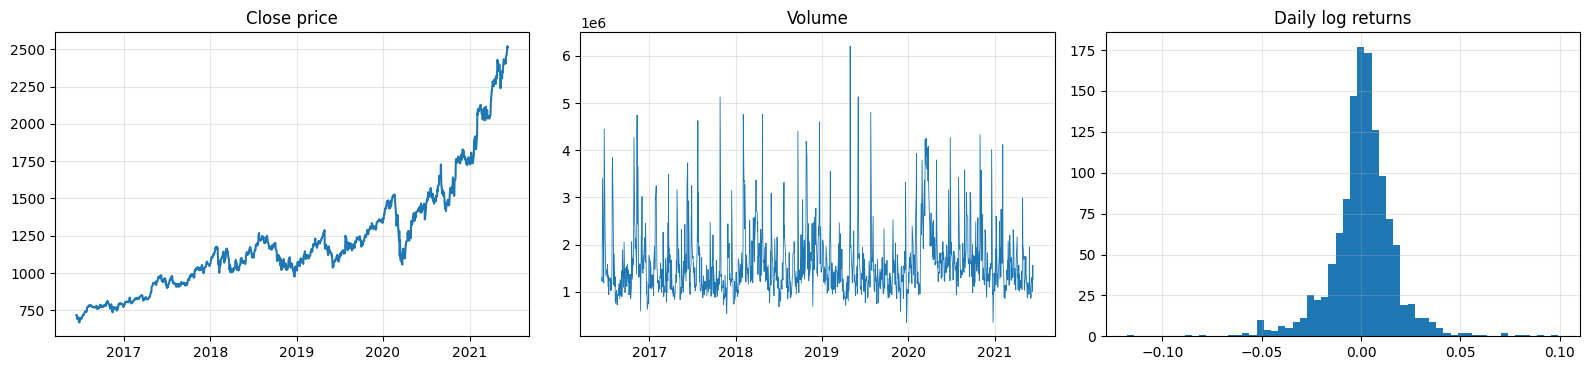

In [2]:
df = pd.read_csv(CSV_PATH)
df["date"] = pd.to_datetime(df["date"], utc=True).dt.tz_localize(None)
df = df.sort_values("date").reset_index(drop=True)
df = df[["date", "open", "high", "low", "close", "volume"]]

print(df.shape, "|", df["date"].min().date(), "->", df["date"].max().date())
print("missing values:", int(df.isna().sum().sum()))
display(df.describe().T.round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(df["date"], df["close"]);                        ax[0].set_title("Close price")
ax[1].plot(df["date"], df["volume"], lw=0.6);               ax[1].set_title("Volume")
ax[2].hist(np.log(df["close"]).diff().dropna(), bins=60);   ax[2].set_title("Daily log returns")
plt.tight_layout(); plt.show()

<a class="anchor" id="sec3"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">3 · Features and targets</p>

Prices trend upward, so a model trained on early prices sees a different range than in later years. Returns are far more stable, so **inputs are returns-based features** and the **target is the cumulative log return** over the next 1..10 days:

`y[h] = log(close[t+h] / close[t])`, for h = 1..10

Predicted prices are `close[t] * exp(y_hat[h])`. The naive baseline ("price stays the same") is simply `y_hat = 0`.

In [3]:
d = df.copy()
d["ret"]      = np.log(d["close"]).diff()                      # daily log return
d["hl"]       = np.log(d["high"] / d["low"])                   # intraday range
d["oc"]       = np.log(d["close"] / d["open"])                 # open->close move
d["dvol"]     = np.log(d["volume"]).diff()                     # volume change
d["vol10"]    = d["ret"].rolling(10).std()                     # past 10-day volatility
d["ma_ratio"] = d["close"] / d["close"].rolling(20).mean() - 1 # distance from 20-day average
delta = d["close"].diff()
gain  = delta.clip(lower=0).rolling(14).mean()
loss  = (-delta.clip(upper=0)).rolling(14).mean()
d["rsi"] = (100 - 100 / (1 + gain / (loss + 1e-12))) / 100 - 0.5   # RSI(14), centred
d = d.dropna().reset_index(drop=True)

FEATURES = ["ret", "hl", "oc", "dvol", "vol10", "ma_ratio", "rsi"]
N_FEAT = len(FEATURES)
print(len(d), "rows after feature warm-up |", N_FEAT, "features:", FEATURES)

1239 rows after feature warm-up | 7 features: ['ret', 'hl', 'oc', 'dvol', 'vol10', 'ma_ratio', 'rsi']


<a class="anchor" id="sec4"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">4 · Walk-forward folds and hold-out test</p>

The timeline is cut in time order. The last 15% is the **hold-out test set**. On the first 85%, an **expanding window** is used: each fold trains on everything before its validation block and validates on the next block, so models are always tested on data that comes after their training data, across several market regimes.

* Scalers and target statistics are fit on each fold's **training rows only**.
* An input window may look back into earlier periods (that is just the past), but a sample's **10-day target always stays inside its own split**.
* A separate **refit split** (all data except the most recent validation block) is used at the end for the final forecast.

In [4]:
close = d["close"].values
ret   = d["ret"].values
feats = d[FEATURES].values
dates = d["date"].values
n = len(d)

first_end = int(n * FIRST_TRAIN_FRAC)
fold_len  = (int(n * (1 - TEST_FRAC)) - first_end) // N_FOLDS
dev_end   = first_end + N_FOLDS * fold_len                 # test set = rows [dev_end, n)
fold_train_ends = [first_end + k * fold_len for k in range(N_FOLDS)]

def make_samples(Xs, lo, hi):
    # last input day t must satisfy t + HORIZON < hi, so targets stay inside [lo, hi)
    idx = np.arange(max(lo, LOOKBACK - 1), hi - HORIZON)
    X   = np.stack([Xs[t - LOOKBACK + 1 : t + 1] for t in idx]).astype("float32")
    y   = np.stack([np.log(close[t + 1 : t + HORIZON + 1] / close[t]) for t in idx]).astype("float32")
    vol = np.array([ret[t + 1 : t + HORIZON + 1].std(ddof=1) for t in idx], dtype="float32")
    return {"idx": idx, "X": X, "y": y, "vol": vol, "c0": close[idx]}

def build_split(train_end, val_end, test_end=None):
    scaler = StandardScaler().fit(feats[:train_end])          # training rows only
    Xs = scaler.transform(feats)
    tr = make_samples(Xs, 0, train_end)
    va = make_samples(Xs, train_end, val_end)
    te = make_samples(Xs, val_end, test_end) if test_end else None
    return {"tr": tr, "va": va, "te": te, "Xs": Xs,
            "y_mu": tr["y"].mean(0), "y_sd": tr["y"].std(0)}

folds = [build_split(e, e + fold_len, n if k == N_FOLDS - 1 else None) for k, e in enumerate(fold_train_ends)]
final = build_split(n - fold_len, n)                          # refit split for the final forecast
LAST  = N_FOLDS - 1

day = lambda i: str(pd.Timestamp(dates[i]).date())
table = []
for k, e in enumerate(fold_train_ends):
    table.append({"fold": k + 1, "train": f"{day(0)} -> {day(e - 1)}", "validation": f"{day(e)} -> {day(e + fold_len - 1)}",
                  "train samples": len(folds[k]["tr"]["X"]), "val samples": len(folds[k]["va"]["X"]),
                  "tuned on": "yes" if k in TUNE_FOLDS else "no"})
display(pd.DataFrame(table).set_index("fold"))
print(f"hold-out test: {day(dev_end)} -> {day(n - 1)} | {len(folds[LAST]['te']['X'])} samples")

,train,validation,train samples,val samples,tuned on
fold,,,,,
1,2016-07-12 -> 2018-09-25,2018-09-26 -> 2019-03-26,488,114,no
2,2016-07-12 -> 2019-03-26,2019-03-27 -> 2019-09-20,612,114,yes
3,2016-07-12 -> 2019-09-20,2019-09-23 -> 2020-03-19,736,114,yes
4,2016-07-12 -> 2020-03-19,2020-03-20 -> 2020-09-15,860,114,no


hold-out test: 2020-09-16 -> 2021-06-11 | 176 samples


<a class="anchor" id="sec5"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">5 · Metrics</p>

All errors are computed **in dollars** after converting predicted returns back to prices, over all 10 horizons:

* **RMSE, MAE, MAPE**: size of the error.
* **rel_RMSE**: RMSE divided by the naive model's RMSE on the same data. **Below 1 means better than "tomorrow = today"**. Because it is scale-free, it can be averaged across folds even though price levels differ a lot between periods; it is the model-selection criterion.
* **MAE_vs_naive**: the same ratio for MAE.
* **R2 (price level)**: will look high for every model because prices trend; it is only a sanity check.
* **DirAcc**: how often the predicted direction of the move (up/down vs the last close) is right, in %.
* **Diebold-Mariano test** (later): whether a model's squared error is significantly lower than a reference model's, with a HAC variance because 10-day targets overlap.

In [5]:
def evaluate(split, yhat):
    """yhat: predicted cumulative log-returns, shape (n, HORIZON). Returns (metrics, rmse_per_horizon)."""
    c0   = split["c0"][:, None]
    true = c0 * np.exp(split["y"])
    pred = c0 * np.exp(yhat)
    err  = pred - true
    naive_err = c0 - true
    rmse = float(np.sqrt((err ** 2).mean()))
    dir_acc = np.nan if np.allclose(yhat, 0) else (np.sign(yhat) == np.sign(split["y"])).mean() * 100
    m = {
        "RMSE": rmse,
        "MAE":  float(np.abs(err).mean()),
        "MAPE": float((np.abs(err) / true).mean() * 100),
        "R2":   float(1 - (err ** 2).sum() / ((true - true.mean()) ** 2).sum()),
        "rel_RMSE": rmse / float(np.sqrt((naive_err ** 2).mean())),
        "MAE_vs_naive": float(np.abs(err).mean() / np.abs(naive_err).mean()),
        "DirAcc": float(dir_acc),
    }
    return m, np.sqrt((err ** 2).mean(0))

def price_err(split, yhat):
    return split["c0"][:, None] * (np.exp(yhat) - np.exp(split["y"]))

def make_row(name, fold, seed, sp, yv, yt=None, params=0, secs=0.0, epochs=np.nan):
    mv, _ = evaluate(sp["va"], yv)
    row = {"model": name, "fold": fold, "seed": seed, "params": params, "train_s": secs, "epochs": epochs}
    row.update({f"val_{k}": v for k, v in mv.items()})
    if yt is not None:
        mt, rh = evaluate(sp["te"], yt)
        row.update({f"test_{k}": v for k, v in mt.items()})
        row["rmse_h_test"] = rh
    return row

def dm_test(err_ref, err_model, max_lag=HORIZON - 1):
    """Diebold-Mariano test on squared price errors averaged over horizons.
    Positive statistic: the model has lower squared error than the reference.
    Bartlett-kernel HAC variance, because targets of neighbouring origins overlap."""
    dd = (err_ref ** 2).mean(1) - (err_model ** 2).mean(1)
    T = len(dd); dc = dd - dd.mean()
    var = (dc @ dc) / T
    for k in range(1, max_lag + 1):
        var += 2 * (1 - k / (max_lag + 1)) * (dc[k:] @ dc[:-k]) / T
    if var <= 0:
        return np.nan, np.nan
    stat = dd.mean() / np.sqrt(var / T)
    return float(stat), float(2 * stats.t.sf(abs(stat), T - 1))

<a class="anchor" id="sec6"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">6 · Baselines</p>

Any neural model has to beat these to be worth its complexity.

* **Naive**: the price stays where it is.
* **Drift**: the average historical trend of the training window continues.
* **Ridge**: a linear model on the flattened 60-day window; the regularisation strength is chosen by walk-forward CV.

In [6]:
rows      = []     # one row per (model, fold, seed)
val_pred  = {}     # (model, seed) -> predictions on the LAST fold's validation block
test_pred = {}     # (model, seed) -> predictions on the hold-out test set

def flat(s):
    return s["X"].reshape(len(s["X"]), -1)

def std_y(sp, s):
    return (s["y"] - sp["y_mu"]) / sp["y_sd"]

def baseline_fn(sp, kind, alpha=None):
    if kind == "Naive":
        return lambda s: np.zeros_like(s["y"])
    if kind == "Drift":
        return lambda s: np.tile(sp["y_mu"], (len(s["y"]), 1))
    ridge = Ridge(alpha=alpha).fit(flat(sp["tr"]), std_y(sp, sp["tr"]))
    return lambda s: ridge.predict(flat(s)) * sp["y_sd"] + sp["y_mu"]

ALPHAS = [1, 10, 100, 1e3, 1e4, 1e5]
ridge_scores = {a: float(np.mean([evaluate(sp["va"], baseline_fn(sp, "Ridge", a)(sp["va"]))[0]["rel_RMSE"] for sp in folds]))
                for a in ALPHAS}
best_alpha = min(ridge_scores, key=ridge_scores.get)
print("Ridge: mean CV rel_RMSE by alpha:", {a: round(v, 4) for a, v in ridge_scores.items()}, "-> alpha =", best_alpha)

for kind in ["Naive", "Drift", "Ridge"]:
    for fi, sp in enumerate(folds):
        f  = baseline_fn(sp, kind, best_alpha)
        yv = f(sp["va"])
        yt = f(sp["te"]) if sp["te"] is not None else None
        rows.append(make_row(kind, fi, 0, sp, yv, yt, params=(LOOKBACK * N_FEAT * HORIZON + HORIZON) if kind == "Ridge" else 0))
        if fi == LAST:
            val_pred[(kind, 0)], test_pred[(kind, 0)] = yv, yt

base_cv = pd.DataFrame(rows).pivot(index="model", columns="fold", values="val_rel_RMSE")
base_cv.columns = [f"fold {k + 1}" for k in base_cv.columns]
display(base_cv.round(3))

Ridge: mean CV rel_RMSE by alpha: {1: 1.6619, 10: 1.4793, 100: 1.2406, 1000.0: 1.1204, 10000.0: 1.025, 100000.0: 0.9979} -> alpha = 100000.0


,fold 1,fold 2,fold 3,fold 4
model,,,,
Drift,1.011,1.004,1.008,0.968
Naive,1.000,1.000,1.000,1.000
Ridge,1.010,1.005,1.003,0.973


<a class="anchor" id="sec7"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">7 · The neural models</p>

| Model | Idea |
|---|---|
| **SimpleRNN** | Vanilla recurrent cell. Suffers from vanishing gradients on long windows. |
| **LSTM** | Gated cell with a separate memory cell; designed to remember longer. |
| **GRU** | Simplified gating (fewer parameters, often similar accuracy). |
| **BiLSTM** | Reads the window forwards and backwards (legal here: the whole window is in the past). |
| **CNN-LSTM** | A convolution extracts local patterns, pooling shortens the sequence, an LSTM models the result. |
| **TCN** | Pure CNN: causal, dilated convolutions with residual blocks, processed in parallel. |
| **Transformer** | Small encoder: self-attention over the 60 days with learned positional embeddings. |

All models share the same input `(60 days x 7 features)` and the same head (`Dense(64) -> Dropout -> Dense(10)`). Each architecture has a default configuration and a small search space (units or filters, depth, dropout, learning rate, weight decay) that is used in the hyperparameter search.

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPUs:", len(tf.config.list_physical_devices("GPU")))

def head(x, n_out, drop):
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(drop)(x)
    return layers.Dense(n_out)(x)

# ---------- recurrent family ----------
def build_rnn(layer_cls, cfg, n_out, bidirectional=False):
    inp = keras.Input((LOOKBACK, N_FEAT))
    x = inp
    for i in range(cfg["layers"]):
        lyr = layer_cls(cfg["units"], return_sequences=(i < cfg["layers"] - 1))
        x = layers.Bidirectional(lyr)(x) if bidirectional else lyr(x)
        x = layers.Dropout(cfg["dropout"])(x)
    return keras.Model(inp, head(x, n_out, cfg["dropout"]))

# ---------- CNN-LSTM ----------
def build_cnn_lstm(cfg, n_out):
    inp = keras.Input((LOOKBACK, N_FEAT))
    x = layers.Conv1D(cfg["filters"], cfg["kernel"], padding="same", activation="relu")(inp)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Dropout(cfg["dropout"])(x)
    x = layers.LSTM(cfg["units"])(x)
    x = layers.Dropout(cfg["dropout"])(x)
    return keras.Model(inp, head(x, n_out, cfg["dropout"]))

# ---------- TCN ----------
def tcn_block(x, filters, kernel, dilation, drop):
    shortcut = x
    for _ in range(2):
        x = layers.Conv1D(filters, kernel, padding="causal", dilation_rate=dilation, activation="relu")(x)
        x = layers.SpatialDropout1D(drop)(x)
    if shortcut.shape[-1] != filters:                        # match channels for the residual add
        shortcut = layers.Conv1D(filters, 1)(shortcut)
    return layers.Activation("relu")(layers.Add()([x, shortcut]))

def build_tcn(cfg, n_out):
    inp = keras.Input((LOOKBACK, N_FEAT))
    x = inp
    for b in range(cfg["blocks"]):
        x = tcn_block(x, cfg["filters"], cfg["kernel"], 2 ** b, cfg["dropout"])
    x = layers.Cropping1D((LOOKBACK - 1, 0))(x)              # last time step has seen the whole causal history
    x = layers.Flatten()(x)
    return keras.Model(inp, head(x, n_out, cfg["dropout"]))

# ---------- Transformer ----------
class PosEmbedding(layers.Layer):
    def __init__(self, length, dim, **kw):
        super().__init__(**kw)
        self.length = length
        self.emb = layers.Embedding(length, dim)
    def call(self, x):
        return x + self.emb(tf.range(self.length))

def build_transformer(cfg, n_out, heads=4):
    dm = cfg["d_model"]
    inp = keras.Input((LOOKBACK, N_FEAT))
    x = layers.Dense(dm)(inp)
    x = PosEmbedding(LOOKBACK, dm)(x)
    for _ in range(cfg["blocks"]):
        h = layers.LayerNormalization()(x)
        h = layers.MultiHeadAttention(num_heads=heads, key_dim=dm // heads, dropout=cfg["dropout"])(h, h)
        x = layers.Add()([x, h])
        h = layers.LayerNormalization()(x)
        h = layers.Dense(cfg["ff"], activation="relu")(h)
        h = layers.Dropout(cfg["dropout"])(h)
        h = layers.Dense(dm)(h)
        x = layers.Add()([x, h])
    x = layers.GlobalAveragePooling1D()(layers.LayerNormalization()(x))
    return keras.Model(inp, head(x, n_out, cfg["dropout"]))

BUILDERS = {
    "SimpleRNN":   lambda c, o: build_rnn(layers.SimpleRNN, c, o),
    "LSTM":        lambda c, o: build_rnn(layers.LSTM, c, o),
    "GRU":         lambda c, o: build_rnn(layers.GRU, c, o),
    "BiLSTM":      lambda c, o: build_rnn(layers.LSTM, c, o, bidirectional=True),
    "CNN-LSTM":    build_cnn_lstm,
    "TCN":         build_tcn,
    "Transformer": build_transformer,
}
MODELS = list(BUILDERS)

# default configuration of every architecture (trial 0 of the search) and its random-search space
DEFAULTS = {
    "SimpleRNN":   dict(units=128, layers=2, dropout=0.2, lr=1e-3, wd=0.0),
    "LSTM":        dict(units=64,  layers=2, dropout=0.2, lr=1e-3, wd=0.0),
    "GRU":         dict(units=72,  layers=2, dropout=0.2, lr=1e-3, wd=0.0),
    "BiLSTM":      dict(units=40,  layers=2, dropout=0.2, lr=1e-3, wd=0.0),
    "CNN-LSTM":    dict(filters=32, kernel=3, units=48, dropout=0.2, lr=1e-3, wd=0.0),
    "TCN":         dict(filters=48, kernel=3, blocks=4, dropout=0.1, lr=1e-3, wd=0.0),
    "Transformer": dict(d_model=48, blocks=2, ff=96, dropout=0.1, lr=1e-3, wd=0.0),
}
_common = dict(dropout=[0.1, 0.2, 0.3], lr=(2e-4, 2e-3), wd=[0.0, 1e-4, 1e-3, 1e-2])   # tuple = log-uniform range
SPACE = {
    "SimpleRNN":   dict(units=[32, 64, 96, 128], layers=[1, 2], **_common),
    "LSTM":        dict(units=[32, 48, 64, 96],  layers=[1, 2], **_common),
    "GRU":         dict(units=[32, 48, 72, 96],  layers=[1, 2], **_common),
    "BiLSTM":      dict(units=[16, 24, 40, 64],  layers=[1, 2], **_common),
    "CNN-LSTM":    dict(filters=[16, 32, 64], kernel=[3, 5], units=[32, 48, 64], **_common),
    "TCN":         dict(filters=[32, 48, 64], kernel=[2, 3, 5], blocks=[3, 4, 5], **_common),
    "Transformer": dict(d_model=[32, 48, 64], blocks=[1, 2, 3], ff=[64, 96, 128], **_common),
}

def sample_config(name, rng):
    cfg = {}
    for k, v in SPACE[name].items():
        cfg[k] = float(np.exp(rng.uniform(np.log(v[0]), np.log(v[1])))) if isinstance(v, tuple) else v[int(rng.integers(len(v)))]
    return cfg

print("parameters (default configs):", {m: BUILDERS[m](DEFAULTS[m], HORIZON).count_params() for m in MODELS})
keras.backend.clear_session()

TensorFlow 2.16.1 | Keras 3.3.3 | GPUs: 2
parameters (default configs): {'SimpleRNN': 59210, 'LSTM': 56266, 'GRU': 54354, 'BiLSTM': 59914, 'CNN-LSTM': 20042, 'TCN': 53946, 'Transformer': 45066}


<a class="anchor" id="sec8"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">8 · Training and hyperparameter search</p>

Every model uses AdamW with gradient clipping, MSE loss on standardised targets, batch size 64, early stopping on the fold's validation loss (best weights restored) and learning-rate halving on plateau.

**Search protocol:** each architecture gets the same budget: its default configuration plus random configurations drawn from its own search space. Each configuration is scored by the mean `rel_RMSE` (RMSE relative to naive) on two tuning folds with one seed. The first and last folds are never used for tuning, so they remain clean for evaluation.

In [8]:
def fit_model(name, cfg, seed, Xtr, ytr_s, Xva, yva_s, n_out=HORIZON):
    keras.utils.set_random_seed(seed)
    model = BUILDERS[name](cfg, n_out)
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=cfg["lr"], weight_decay=cfg["wd"], clipnorm=1.0), loss="mse")
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5),
    ]
    t0 = time.time()
    hist = model.fit(Xtr, ytr_s, validation_data=(Xva, yva_s), epochs=EPOCHS, batch_size=BATCH,
                     callbacks=callbacks, verbose=0)
    return model, hist, time.time() - t0

def run_once(name, cfg, seed, fold_idx, keep_history=False):
    """Train one model on one fold; return predictions (log-return space) and run info."""
    sp = folds[fold_idx]
    model, hist, secs = fit_model(name, cfg, seed, sp["tr"]["X"], std_y(sp, sp["tr"]), sp["va"]["X"], std_y(sp, sp["va"]))
    dec = lambda X: model.predict(X, verbose=0, batch_size=256) * sp["y_sd"] + sp["y_mu"]
    yv = dec(sp["va"]["X"])
    yt = dec(sp["te"]["X"]) if sp["te"] is not None else None
    out = (yv, yt, model.count_params(), secs, len(hist.history["loss"]), hist.history if keep_history else None)
    del model
    keras.backend.clear_session(); gc.collect()
    return out

def ensemble_predict(sp, name, cfg, X_sets):
    """Train len(SEEDS) price models on a split and return the seed-averaged predictions for each array in X_sets."""
    outs = [[] for _ in X_sets]
    for seed in SEEDS:
        model, _, _ = fit_model(name, cfg, seed, sp["tr"]["X"], std_y(sp, sp["tr"]), sp["va"]["X"], std_y(sp, sp["va"]))
        for j, X in enumerate(X_sets):
            outs[j].append(model.predict(X, verbose=0, batch_size=256) * sp["y_sd"] + sp["y_mu"])
        del model
        keras.backend.clear_session(); gc.collect()
    return [np.mean(o, axis=0) for o in outs]

In [9]:
rng = np.random.default_rng(MASTER_SEED)
best_cfg, tuning_log = {}, []
t_start = time.time()

for name in MODELS:
    configs = [DEFAULTS[name]] + [sample_config(name, rng) for _ in range(N_TRIALS - 1)]
    scores = []
    for trial, cfg in enumerate(configs):
        rels = []
        for fi in TUNE_FOLDS:
            yv = run_once(name, cfg, SEEDS[0], fi)[0]
            rels.append(evaluate(folds[fi]["va"], yv)[0]["rel_RMSE"])
        scores.append(float(np.mean(rels)))
        tuning_log.append({"model": name, "trial": trial, "default": trial == 0, "tuning_rel_RMSE": scores[-1], "config": json.dumps(cfg)})
    best = int(np.argmin(scores))
    best_cfg[name] = configs[best]
    print(f"{name:11s} default {scores[0]:.4f} -> best {scores[best]:.4f} (trial {best}) | {time.time() - t_start:6.0f}s elapsed")

tuning_df = pd.DataFrame(tuning_log)
tuned = (tuning_df.loc[tuning_df.groupby("model")["tuning_rel_RMSE"].idxmin()].set_index("model")[["trial", "tuning_rel_RMSE", "config"]]
         .join(tuning_df[tuning_df["default"]].set_index("model")["tuning_rel_RMSE"].rename("default_rel_RMSE")).loc[MODELS])
display(tuned[["default_rel_RMSE", "tuning_rel_RMSE", "trial", "config"]].rename(columns={"tuning_rel_RMSE": "best_rel_RMSE"}))

SimpleRNN   default 1.0026 -> best 0.9986 (trial 2) |    199s elapsed
LSTM        default 1.0030 -> best 0.9965 (trial 3) |    265s elapsed
GRU         default 1.0013 -> best 0.9966 (trial 2) |    336s elapsed
BiLSTM      default 0.9878 -> best 0.9611 (trial 2) |    459s elapsed
CNN-LSTM    default 1.0050 -> best 0.9973 (trial 1) |    533s elapsed
TCN         default 0.9956 -> best 0.9853 (trial 2) |    979s elapsed
Transformer default 0.8965 -> best 0.8965 (trial 0) |   1433s elapsed


,default_rel_RMSE,best_rel_RMSE,trial,config
model,,,,
SimpleRNN,1.002605,0.998560,2,"{""units"": 32, ""layers"": 2, ""dropout"": 0.1, ""lr..."
LSTM,1.002961,0.996531,3,"{""units"": 64, ""layers"": 1, ""dropout"": 0.1, ""lr..."
GRU,1.001333,0.996645,2,"{""units"": 96, ""layers"": 1, ""dropout"": 0.1, ""lr..."
BiLSTM,0.987757,0.961097,2,"{""units"": 16, ""layers"": 2, ""dropout"": 0.2, ""lr..."
CNN-LSTM,1.005026,0.997285,1,"{""filters"": 32, ""kernel"": 5, ""units"": 48, ""dro..."
TCN,0.995580,0.985253,2,"{""filters"": 48, ""kernel"": 3, ""blocks"": 4, ""dro..."
Transformer,0.896479,0.896479,0,"{""d_model"": 48, ""blocks"": 2, ""ff"": 96, ""dropou..."


<a class="anchor" id="sec9"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">9 · Walk-forward cross-validation</p>

The tuned configuration of each architecture is trained on **all four folds with 3 seeds**. Models from the last fold (trained on everything before the last validation block) also produce the hold-out test predictions, which are evaluated later and never used for selection.

In [10]:
hist_last = {}
t_start = time.time()
for name in MODELS:
    for fi in range(N_FOLDS):
        for seed in SEEDS:
            keep = (fi == LAST and seed == SEEDS[0])
            yv, yt, params, secs, ep, h = run_once(name, best_cfg[name], seed, fi, keep_history=keep)
            rows.append(make_row(name, fi, seed, folds[fi], yv, yt, params, secs, ep))
            if fi == LAST:
                val_pred[(name, seed)], test_pred[(name, seed)] = yv, yt
            if keep:
                hist_last[name] = h
    r = pd.DataFrame([x for x in rows if x["model"] == name])
    print(f"{name:11s} mean CV rel_RMSE {r['val_rel_RMSE'].mean():.4f} | {time.time() - t_start:6.0f}s elapsed")

SimpleRNN   mean CV rel_RMSE 1.0133 |    205s elapsed
LSTM        mean CV rel_RMSE 1.0112 |    286s elapsed
GRU         mean CV rel_RMSE 1.0029 |    376s elapsed
BiLSTM      mean CV rel_RMSE 0.9699 |    540s elapsed
CNN-LSTM    mean CV rel_RMSE 1.0021 |    637s elapsed
TCN         mean CV rel_RMSE 1.0015 |   1114s elapsed
Transformer mean CV rel_RMSE 0.9569 |   1541s elapsed


<a class="anchor" id="sec10"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">10 · Walk-forward results</p>

Values are averaged over seeds within each fold. `rel_RMSE` below 1 means the model beats the naive forecast in that period; the models are ranked by its mean over the four folds.

,rel_RMSE (mean),"rel_RMSE (std, folds)",folds beating naive,MAE_vs_naive,DirAcc %,params,train_s,epochs
model,,,,,,,,
Transformer,0.957,0.060,3,0.947,60.161,45066.0,29.307,20.333
BiLSTM,0.970,0.047,3,0.944,61.696,12106.0,9.543,27.250
Drift,0.998,0.020,1,0.981,61.096,0.0,0.000,NaN
Ridge,0.998,0.017,1,0.979,60.570,4210.0,0.000,NaN
Naive,1.000,0.000,0,1.000,NaN,0.0,0.000,NaN
TCN,1.001,0.015,2,0.989,56.842,53946.0,34.595,34.833
CNN-LSTM,1.002,0.018,2,0.982,58.450,20490.0,3.916,15.500
GRU,1.003,0.029,2,0.983,58.735,37098.0,4.045,19.167
LSTM,1.011,0.021,1,0.994,56.564,23242.0,3.440,13.750


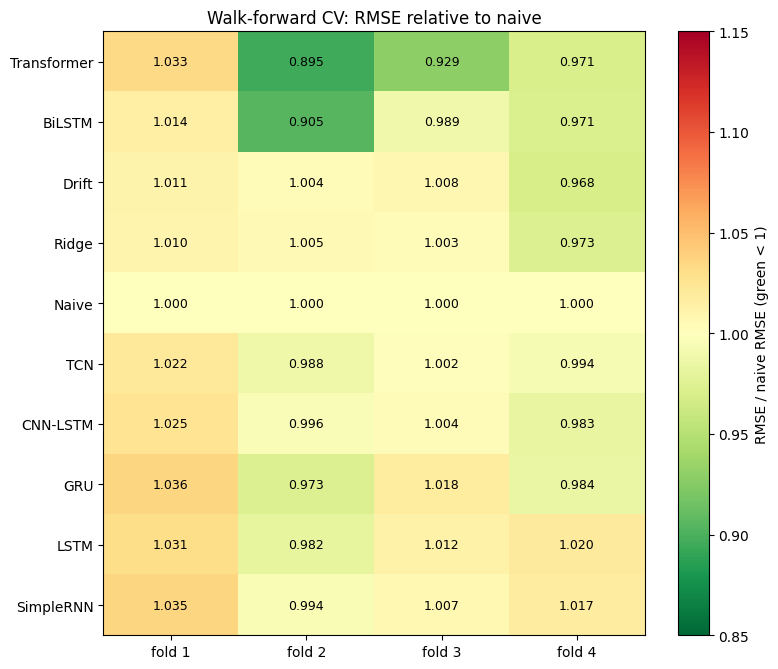

Best neural architecture by mean walk-forward rel_RMSE: Transformer


In [11]:
res = pd.DataFrame(rows)
metric_cols = ["val_rel_RMSE", "val_RMSE", "val_MAE_vs_naive", "val_DirAcc"]
per_fold = res.groupby(["model", "fold"])[metric_cols].mean().reset_index()      # average over seeds
g = per_fold.groupby("model")
cv_summary = pd.DataFrame({
    "rel_RMSE (mean)":         g["val_rel_RMSE"].mean(),
    "rel_RMSE (std, folds)":   g["val_rel_RMSE"].std(),
    "folds beating naive":     g["val_rel_RMSE"].agg(lambda s: int((s < 1).sum())),
    "MAE_vs_naive":            g["val_MAE_vs_naive"].mean(),
    "DirAcc %":                g["val_DirAcc"].mean(),
}).join(res.groupby("model")[["params", "train_s", "epochs"]].mean()).sort_values("rel_RMSE (mean)")
display(cv_summary.round(3))

order = list(cv_summary.index)
heat = per_fold.pivot(index="model", columns="fold", values="val_rel_RMSE").loc[order]
fig, ax = plt.subplots(figsize=(8, 0.5 * len(heat) + 1.8))
im = ax.imshow(heat.values, cmap="RdYlGn_r", vmin=0.85, vmax=1.15, aspect="auto")
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels([f"fold {k + 1}" for k in heat.columns])
ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.3f}", ha="center", va="center", fontsize=9)
ax.grid(False); plt.colorbar(im, label="RMSE / naive RMSE (green < 1)")
ax.set_title("Walk-forward CV: RMSE relative to naive")
plt.tight_layout(); plt.show()

nn_best = cv_summary.loc[MODELS, "rel_RMSE (mean)"].idxmin()
print("Best neural architecture by mean walk-forward rel_RMSE:", nn_best)

<a class="anchor" id="sec11"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">11 · Hold-out test results</p>

The models from the last fold are evaluated once on the untouched test set. Tables show mean ± std over seeds; the second table evaluates the seed-ensemble (average of the seeds' predictions).

,RMSE,MAE,MAPE,R2,rel_RMSE,MAE_vs_naive,DirAcc
Transformer,75.496 ± 1.966,54.206 ± 0.912,2.763 ± 0.043,0.931 ± 0.004,0.969 ± 0.025,0.971 ± 0.016,60.398 ± 2.461
BiLSTM,75.851 ± 0.863,54.624 ± 0.543,2.787 ± 0.026,0.930 ± 0.002,0.974 ± 0.011,0.979 ± 0.010,58.428 ± 3.735
Drift,75.541 ± 0.000,54.312 ± 0.000,2.771 ± 0.000,0.931 ± 0.000,0.970 ± 0.000,0.973 ± 0.000,63.977 ± 0.000
Ridge,75.606 ± 0.000,54.348 ± 0.000,2.774 ± 0.000,0.931 ± 0.000,0.971 ± 0.000,0.974 ± 0.000,63.977 ± 0.000
Naive,77.894 ± 0.000,55.813 ± 0.000,2.843 ± 0.000,0.927 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,nan ± 0.000
TCN,77.008 ± 0.862,55.565 ± 0.504,2.832 ± 0.025,0.928 ± 0.002,0.989 ± 0.011,0.996 ± 0.009,55.265 ± 1.508
CNN-LSTM,75.758 ± 0.220,54.495 ± 0.117,2.779 ± 0.006,0.931 ± 0.000,0.973 ± 0.003,0.976 ± 0.002,61.212 ± 1.168
GRU,76.369 ± 0.476,55.280 ± 0.139,2.820 ± 0.007,0.930 ± 0.001,0.980 ± 0.006,0.990 ± 0.002,55.947 ± 0.978
LSTM,78.088 ± 0.594,56.240 ± 0.239,2.865 ± 0.012,0.926 ± 0.001,1.002 ± 0.008,1.008 ± 0.004,52.689 ± 0.881
SimpleRNN,78.268 ± 0.457,56.515 ± 0.389,2.882 ± 0.021,0.926 ± 0.001,1.005 ± 0.006,1.013 ± 0.007,51.269 ± 2.152


,RMSE,MAE,MAPE,rel_RMSE,MAE_vs_naive,DirAcc
Transformer,75.079,53.784,2.741,0.964,0.964,62.386
BiLSTM,75.688,54.491,2.780,0.972,0.976,61.364
Drift,75.541,54.312,2.771,0.970,0.973,63.977
Ridge,75.606,54.348,2.774,0.971,0.974,63.977
Naive,77.894,55.813,2.843,1.000,1.000,NaN
TCN,76.597,55.129,2.810,0.983,0.988,56.705
CNN-LSTM,75.691,54.426,2.776,0.972,0.975,63.693
GRU,76.017,54.912,2.800,0.976,0.984,56.534
LSTM,77.951,56.099,2.858,1.001,1.005,51.818
SimpleRNN,77.421,55.678,2.838,0.994,0.998,53.523


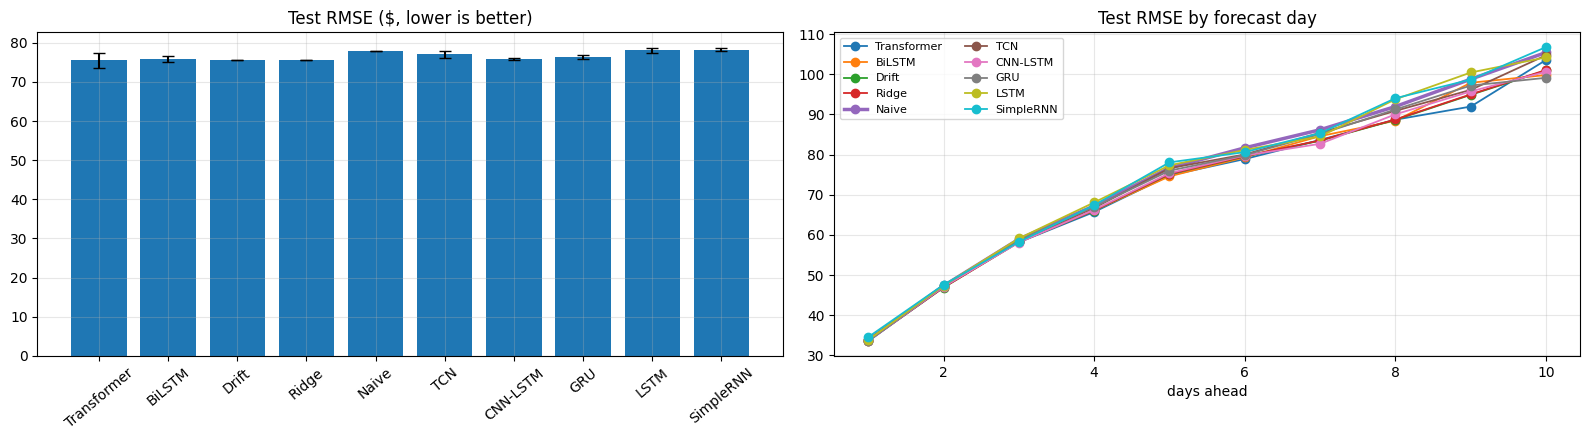

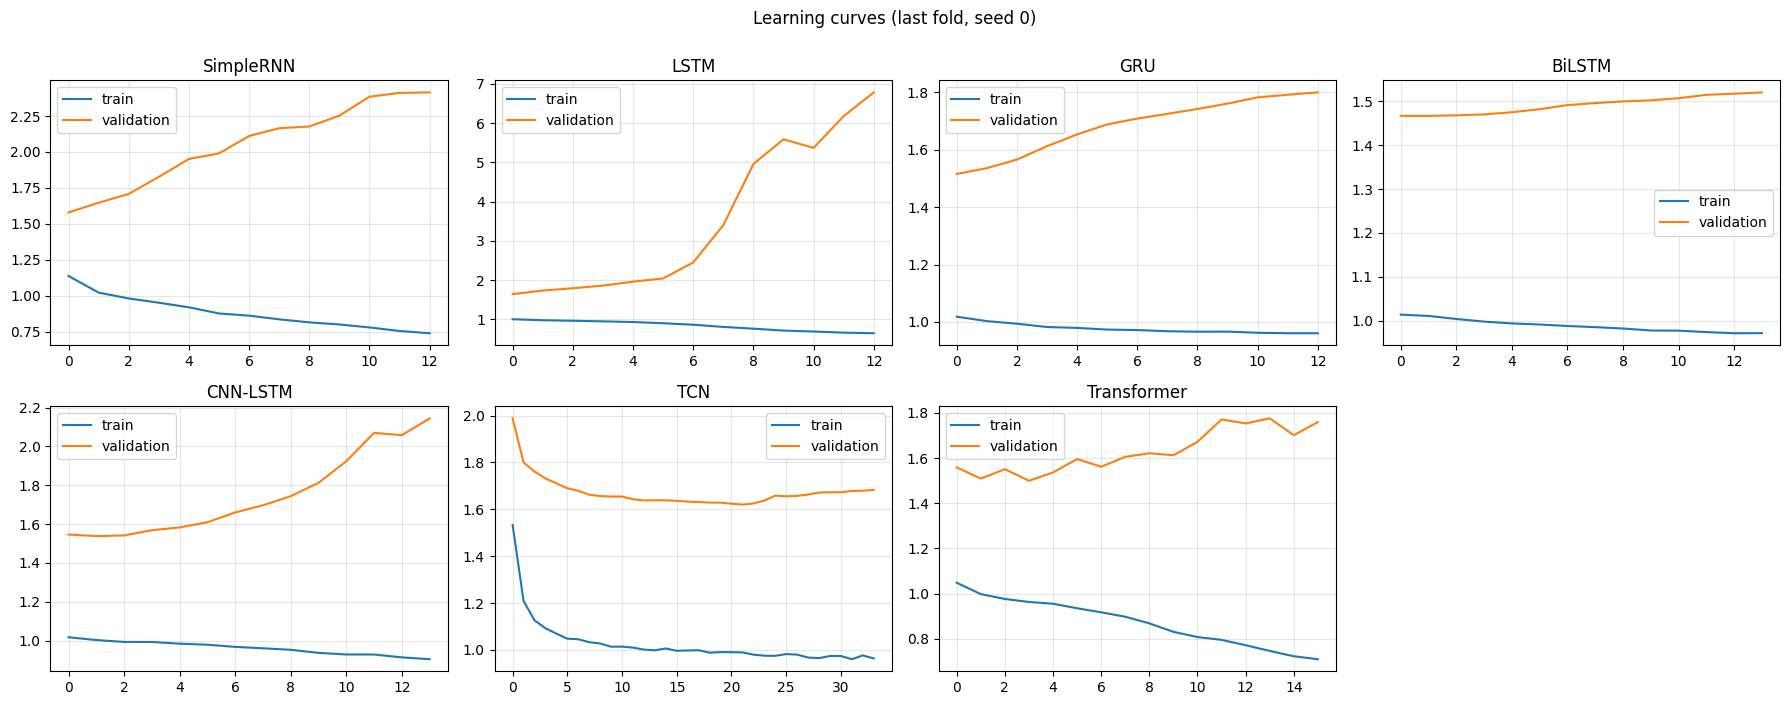

In [12]:
te_sp = folds[LAST]["te"]
test_rows = res[res["fold"] == LAST]
tcols = ["test_RMSE", "test_MAE", "test_MAPE", "test_R2", "test_rel_RMSE", "test_MAE_vs_naive", "test_DirAcc"]
tg = test_rows.groupby("model")
t_mean, t_std = tg[tcols].mean().loc[order], tg[tcols].std().fillna(0.0).loc[order]
pretty = pd.DataFrame({c.replace("test_", ""): [f"{t_mean.loc[m, c]:.3f} ± {t_std.loc[m, c]:.3f}" for m in order] for c in tcols}, index=order)
display(pretty)

ens_test = {m: np.mean([test_pred[(m, s)] for s in (SEEDS if m in MODELS else [0])], axis=0) for m in order}
ens_val  = {m: np.mean([val_pred[(m, s)]  for s in (SEEDS if m in MODELS else [0])], axis=0) for m in order}
ens_tab = pd.DataFrame({m: evaluate(te_sp, ens_test[m])[0] for m in order}).T[["RMSE", "MAE", "MAPE", "rel_RMSE", "MAE_vs_naive", "DirAcc"]]
display(ens_tab.round(3))

# per-horizon error and learning curves
rh = {m: np.mean(np.stack(test_rows[test_rows["model"] == m]["rmse_h_test"].values), 0) for m in order}
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].bar(order, t_mean["test_RMSE"], yerr=t_std["test_RMSE"], capsize=4)
ax[0].set_title("Test RMSE ($, lower is better)"); ax[0].tick_params(axis="x", rotation=40)
for m in order:
    ax[1].plot(range(1, HORIZON + 1), rh[m], marker="o", label=m, lw=2.5 if m == "Naive" else 1.3)
ax[1].set_title("Test RMSE by forecast day"); ax[1].set_xlabel("days ahead"); ax[1].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax_, name in zip(axes.ravel(), MODELS):
    h = hist_last[name]
    ax_.plot(h["loss"], label="train"); ax_.plot(h["val_loss"], label="validation")
    ax_.set_title(name); ax_.legend()
for ax_ in axes.ravel()[len(MODELS):]:
    ax_.axis("off")
fig.suptitle("Learning curves (last fold, seed 0)", y=1.0)
plt.tight_layout(); plt.show()

<a class="anchor" id="sec12"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">12 · Statistical significance</p>

A Diebold-Mariano test asks whether a model's squared error on the test set is significantly lower than that of a reference model (here Naive and Drift). The statistic is **positive when the model is better**. The seed-ensemble predictions are used, and the variance is HAC-corrected because the 10-day targets of neighbouring forecast origins overlap. With a small test set, even sizeable differences can fail to reach significance.

In [13]:
dm_rows = []
for m in order:
    row = {"model": m}
    for ref in ["Naive", "Drift"]:
        if m == ref:
            row[f"vs {ref}: DM stat"], row[f"vs {ref}: p-value"] = np.nan, np.nan
        else:
            row[f"vs {ref}: DM stat"], row[f"vs {ref}: p-value"] = dm_test(price_err(te_sp, ens_test[ref]), price_err(te_sp, ens_test[m]))
    dm_rows.append(row)
dm_df = pd.DataFrame(dm_rows).set_index("model")
display(dm_df.round(3))

,vs Naive: DM stat,vs Naive: p-value,vs Drift: DM stat,vs Drift: p-value
model,,,,
Transformer,2.908,0.004,0.734,0.464
BiLSTM,2.771,0.006,-2.342,0.020
Drift,2.863,0.005,NaN,NaN
Ridge,2.790,0.006,-0.459,0.647
Naive,NaN,NaN,-2.863,0.005
TCN,1.941,0.054,-1.590,0.114
CNN-LSTM,3.028,0.003,-0.912,0.363
GRU,2.761,0.006,-1.537,0.126
LSTM,-0.072,0.942,-1.981,0.049


<a class="anchor" id="sec13"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">13 · Best model on the test set</p>

The architecture with the lowest mean `rel_RMSE` in walk-forward cross-validation is selected. Its seed-ensemble is compared with the naive forecast on the hold-out test set, and its predicted prices are plotted against the actual ones for the 1-day and the 10-day horizon.

Selected architecture: Transformer | tuned config: {'d_model': 48, 'blocks': 2, 'ff': 96, 'dropout': 0.1, 'lr': 0.001, 'wd': 0.0}
Test RMSE: Transformer ensemble $75.08 vs naive $77.89 | rel_RMSE 0.964 | direction accuracy 62.4%


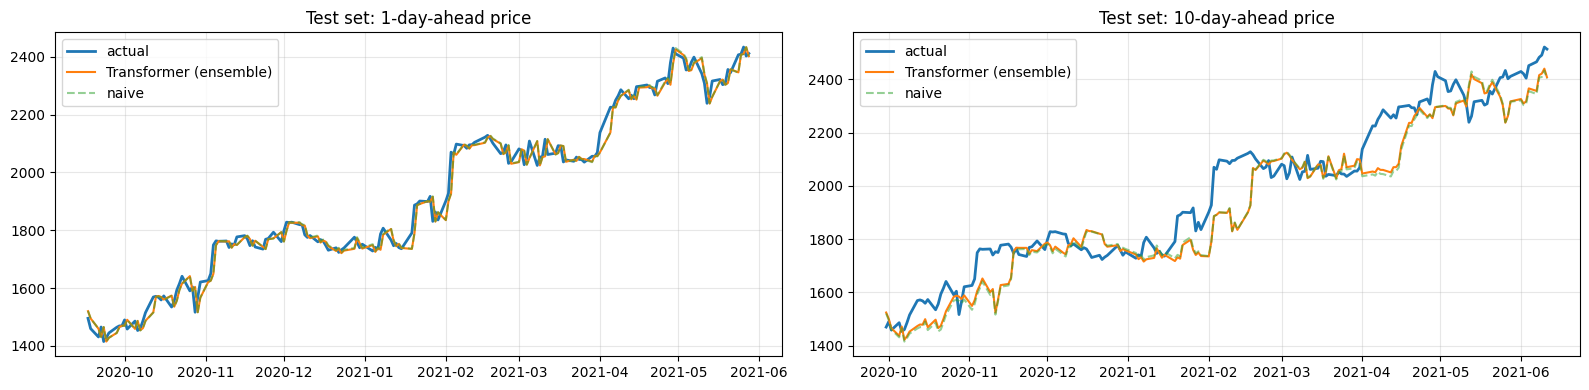

In [14]:
best_name = nn_best
print("Selected architecture:", best_name, "| tuned config:", best_cfg[best_name])

yv_best, yt_best = ens_val[best_name], ens_test[best_name]
m_ens, _ = evaluate(te_sp, yt_best)
m_naive, _ = evaluate(te_sp, ens_test["Naive"])
print(f"Test RMSE: {best_name} ensemble ${m_ens['RMSE']:.2f} vs naive ${m_naive['RMSE']:.2f} | "
      f"rel_RMSE {m_ens['rel_RMSE']:.3f} | direction accuracy {m_ens['DirAcc']:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
for a, h in zip(ax, (1, HORIZON)):
    when = dates[te_sp["idx"] + h]
    a.plot(when, close[te_sp["idx"] + h], label="actual", lw=2)
    a.plot(when, te_sp["c0"] * np.exp(yt_best[:, h - 1]), label=f"{best_name} (ensemble)")
    a.plot(when, te_sp["c0"], label="naive", alpha=0.5, ls="--")
    a.set_title(f"Test set: {h}-day-ahead price"); a.legend()
plt.tight_layout(); plt.show()

<a class="anchor" id="sec14"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">14 · Forecast 1: next 10 trading days (price) with an 80% band</p>

**Interval check.** The band is built from the validation residuals of the best model (10th and 90th percentile of the error at each horizon). Its honesty is checked on the hold-out test set: if it is well calibrated, about 80% of test outcomes fall inside it.

**Final forecast.** The best architecture is then refit on all data except the most recent validation block (early stopping on that block), and the same residual method gives the band. The dataset ends on 2021-06-11, so the forecast covers the 10 trading days that follow that date.

Test coverage of the 80% band by horizon (%): [81. 85. 84. 78. 70. 74. 75. 77. 78. 80.] | overall: 78.1

Last close (2021-06-11): 2513.93


,date,forecast,low_80,high_80
0,2021-06-14,2506.979980,2466.98,2562.32
1,2021-06-15,2501.080078,2434.36,2568.82
2,2021-06-16,2488.229980,2421.65,2576.81
3,2021-06-17,2477.679932,2407.11,2603.03
4,2021-06-18,2471.979980,2387.11,2635.22
5,2021-06-21,2461.389893,2382.43,2627.16
6,2021-06-22,2450.600098,2383.68,2624.29
7,2021-06-23,2437.989990,2363.87,2609.70
8,2021-06-24,2447.929932,2356.36,2619.09
9,2021-06-25,2445.080078,2364.43,2627.13


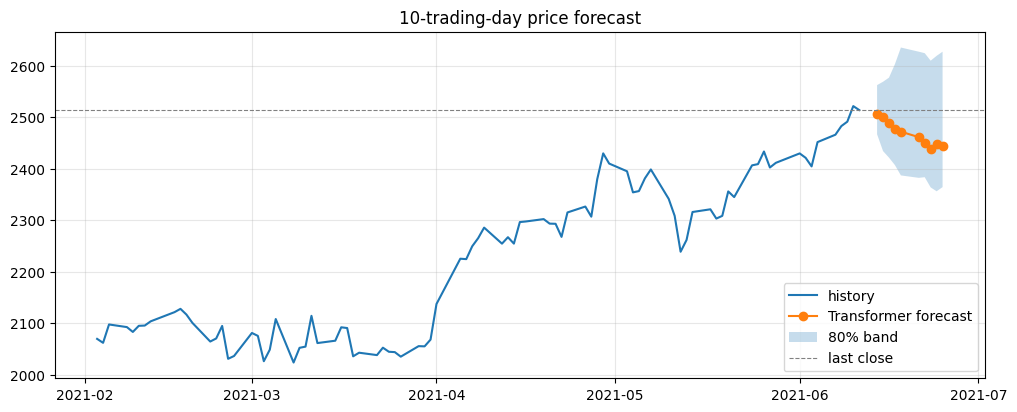

In [15]:
# --- interval check: fold-4 models, band from validation residuals, coverage on the hold-out test set ---
res_val = folds[LAST]["va"]["y"] - yv_best
q_lo, q_hi = np.quantile(res_val, 0.10, axis=0), np.quantile(res_val, 0.90, axis=0)
inside = ((te_sp["y"] >= yt_best + q_lo) & (te_sp["y"] <= yt_best + q_hi)).mean(0)
coverage = float(inside.mean() * 100)
print("Test coverage of the 80% band by horizon (%):", np.round(inside * 100, 0), "| overall:", round(coverage, 1))

# --- final forecast: refit on the most recent data ---
x_last = final["Xs"][-LOOKBACK:][None].astype("float32")
yv_fin, y_next = ensemble_predict(final, best_name, best_cfg[best_name], [final["va"]["X"], x_last])
y_next = y_next[0]
res_fin = final["va"]["y"] - yv_fin
f_lo, f_hi = np.quantile(res_fin, 0.10, axis=0), np.quantile(res_fin, 0.90, axis=0)

last_close = close[-1]
fc_dates = pd.bdate_range(pd.Timestamp(dates[-1]) + pd.Timedelta(days=1), periods=HORIZON)
fc, fc_lo, fc_hi = (last_close * np.exp(y_next + q) for q in (0, f_lo, f_hi))

forecast = pd.DataFrame({"date": fc_dates.date, "forecast": fc.round(2), "low_80": fc_lo.round(2), "high_80": fc_hi.round(2)})
print(f"\nLast close ({day(n - 1)}): {last_close:.2f}")
display(forecast)

hist_n = 90
plt.figure(figsize=(12, 4.5))
plt.plot(dates[-hist_n:], close[-hist_n:], label="history")
plt.plot(fc_dates, fc, marker="o", label=f"{best_name} forecast")
plt.fill_between(fc_dates, fc_lo, fc_hi, alpha=0.25, label="80% band")
plt.axhline(last_close, color="gray", ls="--", lw=0.8, label="last close")
plt.title("10-trading-day price forecast"); plt.legend(); plt.show()

<a class="anchor" id="sec15"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">15 · Forecast 2: next-10-day volatility</p>

Volatility (how much the price swings) is typically more predictable than direction because it clusters: calm periods follow calm periods. The target is the standard deviation of the next 10 daily log returns, modelled in log space. The selected architecture (with its tuned configuration) is retrained for this single output and compared against two baselines: **persistence** (volatility stays at its recent 10-day level) and the **train mean**.

,RMSE,MAE,corr
model,,,
Transformer,0.00748,0.00562,0.22654
Persistence (last 10d vol),0.00885,0.00696,0.00974
Train mean,0.00696,0.00522,NaN


Forecast volatility for the next 10 trading days: 1.47% per day (about 23% annualised)


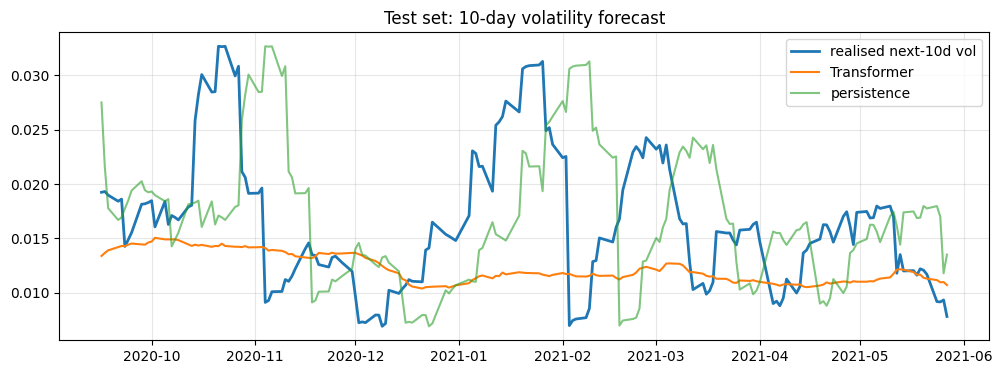

In [16]:
def vol_ensemble_predict(sp, name, cfg, X_sets):
    lv_tr, lv_va = np.log(sp["tr"]["vol"])[:, None], np.log(sp["va"]["vol"])[:, None]
    mu, sd = float(lv_tr.mean()), float(lv_tr.std())
    outs = [[] for _ in X_sets]
    for seed in SEEDS:
        model, _, _ = fit_model(name, cfg, seed, sp["tr"]["X"], (lv_tr - mu) / sd, sp["va"]["X"], (lv_va - mu) / sd, n_out=1)
        for j, X in enumerate(X_sets):
            outs[j].append(model.predict(X, verbose=0, batch_size=256).ravel() * sd + mu)
        del model
        keras.backend.clear_session(); gc.collect()
    return [np.exp(np.mean(o, axis=0)) for o in outs]

vol10_raw = d["vol10"].values
sp_last = folds[LAST]
vol_test_pred = vol_ensemble_predict(sp_last, best_name, best_cfg[best_name], [te_sp["X"]])[0]
cands = {
    best_name: vol_test_pred,
    "Persistence (last 10d vol)": vol10_raw[te_sp["idx"]],
    "Train mean": np.full(len(te_sp["vol"]), float(sp_last["tr"]["vol"].mean())),
}
vol_rows = []
for k, p in cands.items():
    e = p - te_sp["vol"]
    vol_rows.append({"model": k, "RMSE": float(np.sqrt((e ** 2).mean())), "MAE": float(np.abs(e).mean()),
                     "corr": float(np.corrcoef(p, te_sp["vol"])[0, 1]) if np.std(p) > 0 else np.nan})
vol_df = pd.DataFrame(vol_rows).set_index("model")
display(vol_df.round(5))

vol_next = float(vol_ensemble_predict(final, best_name, best_cfg[best_name], [x_last])[0][0])
print(f"Forecast volatility for the next {HORIZON} trading days: {vol_next * 100:.2f}% per day "
      f"(about {vol_next * np.sqrt(252) * 100:.0f}% annualised)")

plt.figure(figsize=(12, 4))
plt.plot(dates[te_sp["idx"]], te_sp["vol"], label="realised next-10d vol", lw=2)
plt.plot(dates[te_sp["idx"]], cands[best_name], label=best_name)
plt.plot(dates[te_sp["idx"]], cands["Persistence (last 10d vol)"], label="persistence", alpha=0.6)
plt.title("Test set: 10-day volatility forecast"); plt.legend(); plt.show()

<a class="anchor" id="sec16"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">16 · Summary of results</p>

The summary below is generated from the results above.

In [17]:
def pct_lower(a, b):
    return (1 - a / b) * 100

def vs_txt(a, b):
    diff = pct_lower(a, b)
    return f"{abs(diff):.0f}% {'lower' if diff >= 0 else 'higher'}"

def ptxt(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

cvb = cv_summary.loc[best_name]
best_test = test_rows[test_rows["model"] == best_name]
rmse_mean, rmse_std = best_test["test_RMSE"].mean(), best_test["test_RMSE"].std()
stat_n, p_n = dm_df.loc[best_name, "vs Naive: DM stat"], dm_df.loc[best_name, "vs Naive: p-value"]
stat_d, p_d = dm_df.loc[best_name, "vs Drift: DM stat"], dm_df.loc[best_name, "vs Drift: p-value"]

def verdict(stat, p, ref):
    if np.isnan(p):
        return f"no test possible against {ref}"
    if p < 0.05:
        return f"significantly {'better' if stat > 0 else 'worse'} than {ref} ({ptxt(p)})"
    return f"not significantly different from {ref} ({ptxt(p)})"

ranked = [f"{m} ({cv_summary.loc[m, 'rel_RMSE (mean)']:.3f})" for m in cv_summary.index]
lines = [
    f"1. Walk-forward CV ranking by mean RMSE relative to naive (lower is better): " + ", ".join(ranked) + ".",
    f"2. Selected architecture: {best_name} (tuned config: {best_cfg[best_name]}). It beats naive in {int(cvb['folds beating naive'])} of {N_FOLDS} folds.",
    f"3. Hold-out test: {best_name} RMSE ${rmse_mean:.2f} ± {rmse_std:.2f} over seeds (${m_ens['RMSE']:.2f} as ensemble) vs ${m_naive['RMSE']:.2f} for naive, "
    f"i.e. {pct_lower(m_ens['RMSE'], m_naive['RMSE']):.1f}% lower for the ensemble; directional accuracy {m_ens['DirAcc']:.1f}%.",
    f"4. Significance on the test set: {verdict(stat_n, p_n, 'Naive')}; {verdict(stat_d, p_d, 'Drift')}.",
    f"5. Drift baseline test RMSE ${evaluate(te_sp, ens_test['Drift'])[0]['RMSE']:.2f}; Ridge ${evaluate(te_sp, ens_test['Ridge'])[0]['RMSE']:.2f}.",
    f"6. The 80% interval covered {coverage:.1f}% of test outcomes.",
    f"7. Price forecast from the last close of {last_close:.2f} ({day(n - 1)}): day 1 {fc[0]:.2f}, day {HORIZON} {fc[-1]:.2f} "
    f"(80% band {fc_lo[-1]:.2f} to {fc_hi[-1]:.2f}).",
    f"8. Volatility: {best_name} RMSE {vol_df.loc[best_name, 'RMSE']:.5f} vs {vol_df.loc['Train mean', 'RMSE']:.5f} (train mean, "
    f"{vs_txt(vol_df.loc[best_name, 'RMSE'], vol_df.loc['Train mean', 'RMSE'])}) and {vol_df.loc['Persistence (last 10d vol)', 'RMSE']:.5f} "
    f"(persistence, {vs_txt(vol_df.loc[best_name, 'RMSE'], vol_df.loc['Persistence (last 10d vol)', 'RMSE'])}); "
    f"forecast {vol_next * 100:.2f}% per day (about {vol_next * np.sqrt(252) * 100:.0f}% annualised).",
]
print("\n".join(lines))

# export artefacts
cv_summary.to_csv("results/walk_forward_cv_summary.csv")
pretty.to_csv("results/test_results.csv")
dm_df.to_csv("results/diebold_mariano.csv")
tuned.to_csv("results/hyperparameter_search_best.csv")
forecast.to_csv("results/price_forecast_10d.csv", index=False)
with open("results/best_hyperparameters.json", "w") as f:
    json.dump(best_cfg, f, indent=2)

1. Walk-forward CV ranking by mean RMSE relative to naive (lower is better): Transformer (0.957), BiLSTM (0.970), Drift (0.998), Ridge (0.998), Naive (1.000), TCN (1.001), CNN-LSTM (1.002), GRU (1.003), LSTM (1.011), SimpleRNN (1.013).
2. Selected architecture: Transformer (tuned config: {'d_model': 48, 'blocks': 2, 'ff': 96, 'dropout': 0.1, 'lr': 0.001, 'wd': 0.0}). It beats naive in 3 of 4 folds.
3. Hold-out test: Transformer RMSE $75.50 ± 1.97 over seeds ($75.08 as ensemble) vs $77.89 for naive, i.e. 3.6% lower for the ensemble; directional accuracy 62.4%.
4. Significance on the test set: significantly better than Naive (p = 0.004); not significantly different from Drift (p = 0.464).
5. Drift baseline test RMSE $75.54; Ridge $75.61.
6. The 80% interval covered 78.1% of test outcomes.
7. Price forecast from the last close of 2513.93 (2021-06-11): day 1 2506.98, day 10 2445.08 (80% band 2364.43 to 2627.13).
8. Volatility: Transformer RMSE 0.00748 vs 0.00696 (train mean, 8% higher) and

<a class="anchor" id="sec17"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">17 · Conclusions</p>

**Model comparison (walk-forward CV, 4 folds x 3 seeds)**

* The Transformer had the lowest mean RMSE relative to naive (0.957, better than naive in 3 of 4 folds) and was selected, followed by BiLSTM (0.970, 3 of 4). Every other neural model stayed within about 1% of the naive forecast (TCN 1.001, CNN-LSTM 1.002, GRU 1.003, LSTM 1.011, SimpleRNN 1.013), and Drift and Ridge sit at 0.998. Ridge's best regularisation strength was the largest value in the grid (alpha = 1e5), which makes it an almost constant forecast; this is consistent with little linear signal in the window features.
* The advantage of the two best models is **not uniform across periods**. The Transformer gains 10% and 7% over naive in folds 2 and 3 (March 2019 to March 2020) and BiLSTM 9% in fold 2 (1% in fold 3), but both are worse than naive in fold 1 (1.033 and 1.014) and only match Drift in fold 4 (0.971 vs 0.968). On the two folds not used for hyperparameter tuning (1 and 4), the ranking is Drift (0.990), Ridge (0.992), BiLSTM (0.993) and Transformer (1.002).
* Tuning helped most for BiLSTM (tuning score 0.988 to 0.961, with a small 16-unit configuration). For the Transformer, the default configuration was already the best of the trials, and several architectures gained little from the search, which points to a weak signal rather than to under-tuned models.

**Hold-out test set (Sep 2020 to Jun 2021)**

* The Transformer ensemble reached RMSE $75.08 against $77.89 for naive (3.6% lower; Diebold-Mariano p = 0.004), with 62.4% directional accuracy.
* It is **statistically indistinguishable from the Drift baseline** ($75.54; p = 0.46). BiLSTM, CNN-LSTM, GRU, Ridge and Drift are also significantly better than naive (p <= 0.006), which indicates that most of the gain over naive comes from the steady uptrend of the test period that a zero-parameter drift also captures. LSTM and SimpleRNN do not beat naive, and TCN is borderline (p = 0.054).
* Directional accuracy of the neural models (about 51-64%) does not exceed the 64% obtained by always predicting "up" in this period.

**Training behaviour**

* For almost every model, the validation loss is lowest within the first few epochs and then rises while the training loss keeps falling, so early stopping with best-weight restoration determines the final models. The last validation block (March to September 2020: the COVID crash and recovery) is also far from the training distribution, so validation loss stays above training loss throughout.
* Training cost differs widely: about 3-4 s per run for LSTM, GRU and CNN-LSTM versus roughly 30-35 s for the Transformer and TCN on the same GPU.

**Forecasts**

* The 80% interval covered 78.1% of test outcomes (70-85% depending on the horizon), close to its nominal level and slightly too narrow at horizons 5-7.
* The refit Transformer forecasts a mild decline from the last close of 2,513.93 to about 2,445 at day 10, but the last close lies inside the 80% band at every horizon, and the model's directional accuracy does not beat a constant "up" call, so the point forecast should be read as a central estimate with uncertainty rather than as a trading signal.
* Volatility: the Transformer's RMSE (0.00748) is 15% lower than persistence (0.00885) and its correlation with realised volatility is 0.23 (persistence: 0.01), so it carries some ranking information. However, it does **not** improve on a constant train-mean forecast in RMSE or MAE (0.00696 and 0.00522), so in this experiment volatility is not forecast better than the long-run level. The forecast for the next 10 trading days is about 1.47% per day (roughly 23% annualised).

**Overall**

The pipeline (leak-free walk-forward evaluation, equal tuning budget, seeds, significance tests, calibrated intervals) shows that, for daily GOOG data, sequence models add at most a small, regime-dependent edge over simple trend baselines. A Transformer or BiLSTM can beat naive, but none of the neural models demonstrably beats a drift forecast.

<a class="anchor" id="sec18"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">18 · Limitations and possible extensions</p>

**Limitations**

* One stock, about 1,200 daily observations and a short, regime-dependent history: rankings between close models are not statistically reliable, which is why seeds, walk-forward folds and significance tests are reported.
* Validation folds and the test set cover different market regimes, so a model that is best in one period is not necessarily best in another.
* Hyperparameter search uses a small random budget on two folds; a larger search could change the ranking.
* No transaction costs or trading strategy are modelled. The forecasts are for research and illustration only, not financial advice.

**Possible extensions**

More tickers and longer histories, a cost-aware backtest, Bayesian hyperparameter optimisation, probabilistic models (quantile loss, conformal prediction) and additional exogenous features.